# Damped Newton Method

The difference it have from Pure newtons method is that you can directly start from anywhere in the function (for non-linear ones) and still touch the minima.

- We use a linesearch method to get the step size

In [21]:
import numpy as np
import matplotlib.pyplot as plt

def f(x, y):
    # If we accidentally step outside the domain boundary, return infinity
    return np.exp(0.5*x + 0.5*y) - np.log(4 - x**2 - y**2)

def gradient(x, y):
    denom = 4 - x**2 - y**2
    df_dx = 0.5 * np.exp(0.5*x + 0.5*y) + (2*x / denom)
    df_dy = 0.5 * np.exp(0.5*x + 0.5*y) + (2*y / denom)
    return np.array([df_dx, df_dy])

def hessian(x, y):
    denom = 4 - x**2 - y**2
    exp_term = 0.5 * 0.5 * np.exp(0.5*x + 0.5*y)
    
    # Partial derivatives using quotient/chain rule
    d2f_dx2 = exp_term + (2 * denom + 4*x**2) / (denom**2)
    d2f_dy2 = exp_term + (2 * denom + 4*y**2) / (denom**2)
    d2f_dxdy = exp_term + (4*x*y) / (denom**2)
    d2f_dydx = d2f_dxdy
    
    return np.array([[d2f_dx2, d2f_dxdy],
                    [d2f_dydx, d2f_dy2]])

tol = 1e-6
k=0
max_iter = 1000
point = np.array([1.35, -1.35])

#for backtracking
c = 1e-2
p = 0.6

history_of_x = [point[0]]
history_of_y = [point[1]]
history_of_z = [f(point[0],point[1])]

while np.linalg.norm(gradient(point[0], point[1])) > tol and max_iter>k:

    #direction:
    direction = - np.dot(np.linalg.inv(hessian(point[0], point[1])), gradient(point[0], point[1]))

    alpha = 1

    #now lets loop till we get perfect alpha for our current position:
    while True:
        new_pos = point + (alpha * direction)

        #new we check our alpha if it need to be reduced or not
        if f(new_pos[0], new_pos[1]) > f(point[0], point[1]) + c * alpha * np.dot(np.transpose(gradient(point[0], point[1])),direction):
            alpha = p * alpha
        else:
            break

    #we got a updated alpha lets use it
    new_pos = point + (alpha * direction)

    #update
    point = new_pos
    print(f'[Epoch {k}]: Current alpha: {alpha}, Current Point: {point}, Current Height: {f(point[0], point[1])}')

    k = k + 1

    #save data:
    history_of_x.append(point[0])
    history_of_y.append(point[1])
    history_of_z.append(f(point[0],point[1]))


[Epoch 0]: Current alpha: 1, Current Point: [ 1.20579647 -1.36882747], Current Height: 1.318670514020593
[Epoch 1]: Current alpha: 1, Current Point: [ 0.95268216 -1.3702092 ], Current Height: 0.6169060745527251
[Epoch 2]: Current alpha: 1, Current Point: [ 0.5517241 -1.2962865], Current Height: -0.011578777691803932
[Epoch 3]: Current alpha: 1, Current Point: [ 0.02802942 -1.06107844], Current Height: -0.45888016438245693
[Epoch 4]: Current alpha: 1, Current Point: [-0.40494129 -0.70254212], Current Height: -0.6319111331788334
[Epoch 5]: Current alpha: 1, Current Point: [-0.51462892 -0.52849358], Current Height: -0.6464758363414964
[Epoch 6]: Current alpha: 1, Current Point: [-0.5167864  -0.51682697], Current Height: -0.646527673520076
[Epoch 7]: Current alpha: 1, Current Point: [-0.51678831 -0.51678831], Current Height: -0.6465276741131745


C:\Users\surya\AppData\Local\Temp\ipykernel_16456\2607033428.py:6: RuntimeWarning: invalid value encountered in log
  return np.exp(0.5*x + 0.5*y) - np.log(4 - x**2 - y**2)


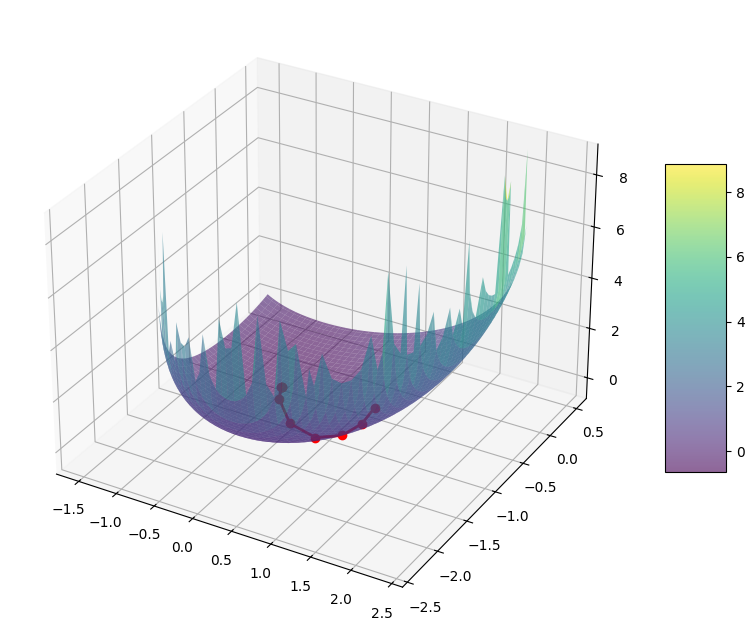

In [22]:
fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(projection='3d')

X_surf = np.linspace(min(history_of_x)-1, max(history_of_x)+1, 100)
Y_surf= np.linspace(min(history_of_y)-1, max(history_of_y)+1, 100)

X,Y = np.meshgrid(X_surf,Y_surf)
Z = f(X,Y)

surf = ax.plot_surface(X,Y,Z, cmap='viridis', alpha=0.6) #the 3d land
fig.colorbar(surf, ax=ax, shrink= 0.5, aspect=5)

ax.plot(history_of_x,history_of_y,history_of_z, color = 'Red', marker='o', linewidth = 2,label='AGD Path') #add a marker if want

plt.show()

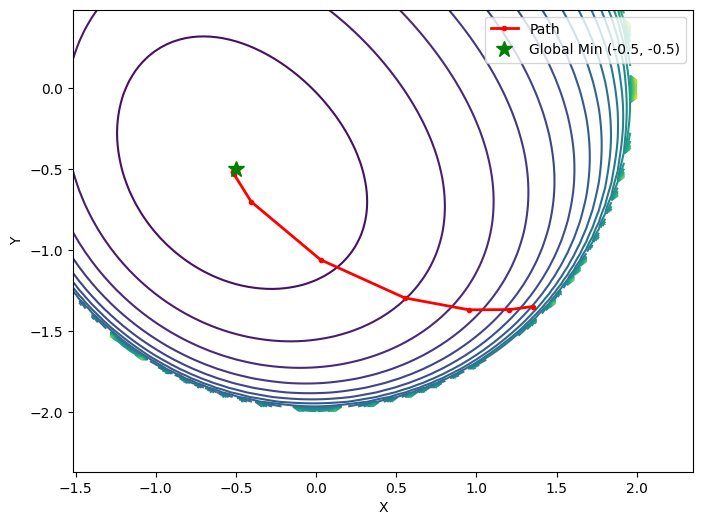

In [25]:
fig,ax = plt.subplots(figsize = (8,6))
cp = ax.contour(X,Y,Z, levels=30,cmap='viridis')
ax.plot(history_of_x, history_of_y, 'ro-', linewidth=2, markersize=3, label='Path')
ax.plot(-0.5, -0.5, 'g*', markersize=12, label='Global Min (-0.5, -0.5)')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.legend()
plt.show()